In [1]:
from volta.prelude import *
from volta.planning.footsteps_planner import *
from volta.planning.ismpc import *
# from UtilsFunction.IntrinsicallyStableMPC.footstep_planner import *  # moved to legacy/ (not importable from volta)
import time
import copy

In [2]:
params = {
    'g': 9.81,
    'h': 0.72,
    'foot_size': 0.1,
    'step_height': 0.02,
    'ss_duration': 70,
    'ds_duration': 30,
    'mpc_time_step': 0.02,
    'first_swing': 'rfoot',
    'µ': 0.5,
    'N': 100,
    'dof': 18,
}
params['eta'] = np.sqrt(params['g'] / params['h'])
initial = {
            'lfoot': {'pos': np.array([1,0,0,0,0.125,0]),
                      'vel': np.zeros(6),
                      'acc': np.zeros(6)},
            'rfoot': {'pos': np.array([1,0,0,0,-0.125,0]),
                      'vel': np.zeros(6),
                      'acc': np.zeros(6)},
            'com'  : {'pos': np.array([0,0,0.3]),
                      'vel': np.zeros(6),
                      'acc': np.zeros(3)},
            'torso': {'pos': np.array([1,0,0,0]),
                      'vel': np.zeros(3),
                      'acc': np.zeros(3)},
            'base' : {'pos': np.array([1,0,0,0,0,0,0]),
                      'vel': np.zeros(3),
                      'acc': np.zeros(3)},
            'joint': {'pos': np.zeros(12),
                      'vel': np.zeros(12),
                      'acc': np.zeros(12)},
            'zmp'  : {'pos': np.zeros(3),
                      'vel': np.zeros(3),
                      'acc': np.zeros(3)}
        }
desired = copy.deepcopy(initial)
current = copy.deepcopy(initial)
# initialize footstep planner
reference = [(0.1, 0., 0.0)] * 5 #+ [(0.2, 0., -0.0)] * 10 + [(0.1, 0., 0.)] * 10
# reference = [(0.05, 0., 0.0)] * 5 + [(0.05, 0., -0.0)] * 20 
# footstep_planner = FootstepPlanner(
#     reference,
#     initial['lfoot']['pos'],
#     initial['rfoot']['pos'],
#     params
#     )


9
Plot saved to: /home/tanawatp/Pictures/Thesis_final/FootstepsPlanned/straight.png


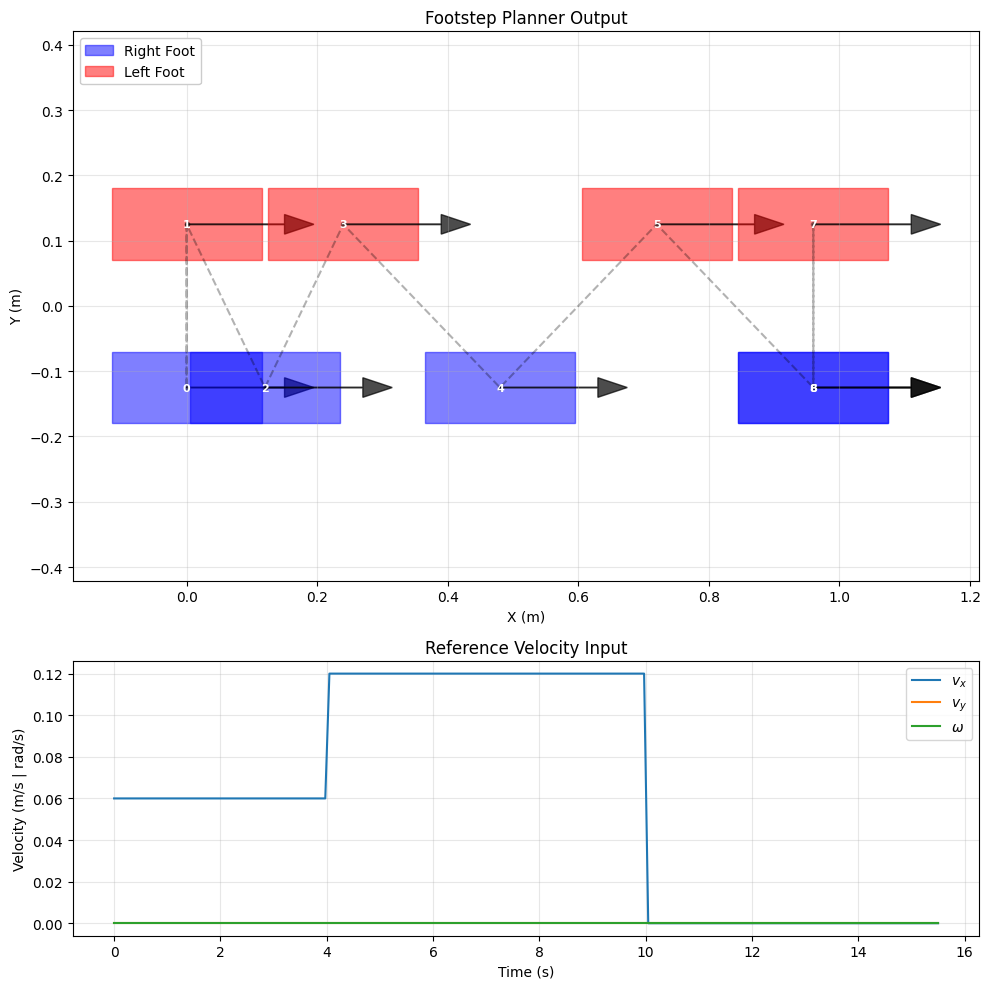

9
Plot saved to: /home/tanawatp/Pictures/Thesis_final/FootstepsPlanned/diagonal.png


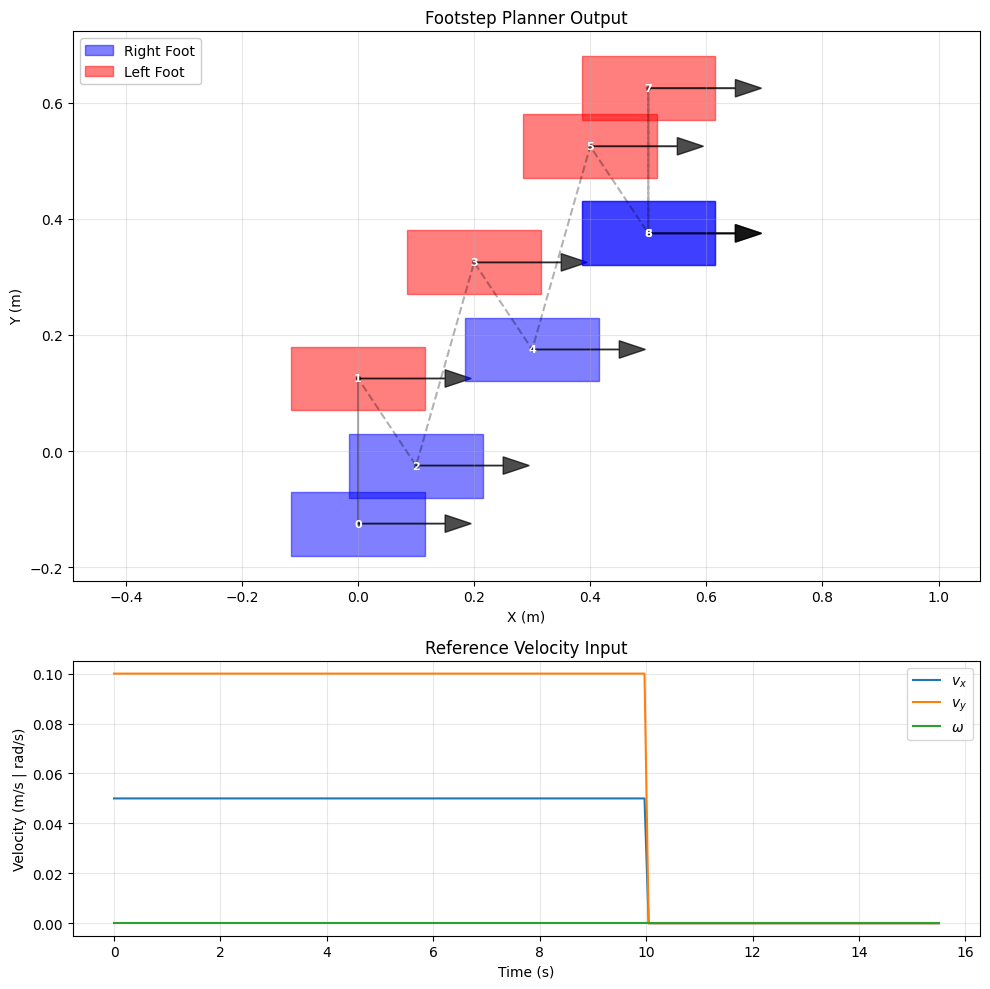

9
Plot saved to: /home/tanawatp/Pictures/Thesis_final/FootstepsPlanned/circular.png


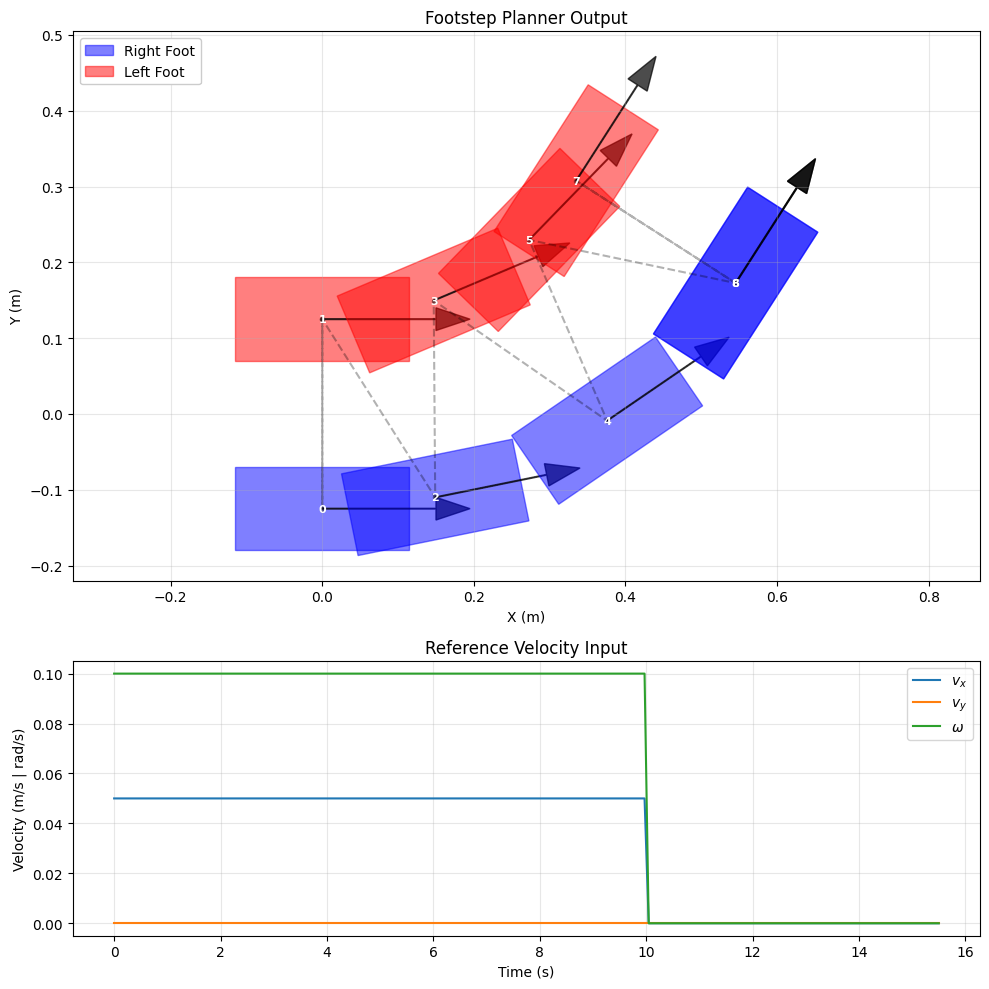

9
Plot saved to: /home/tanawatp/Pictures/Thesis_final/FootstepsPlanned/rotational.png


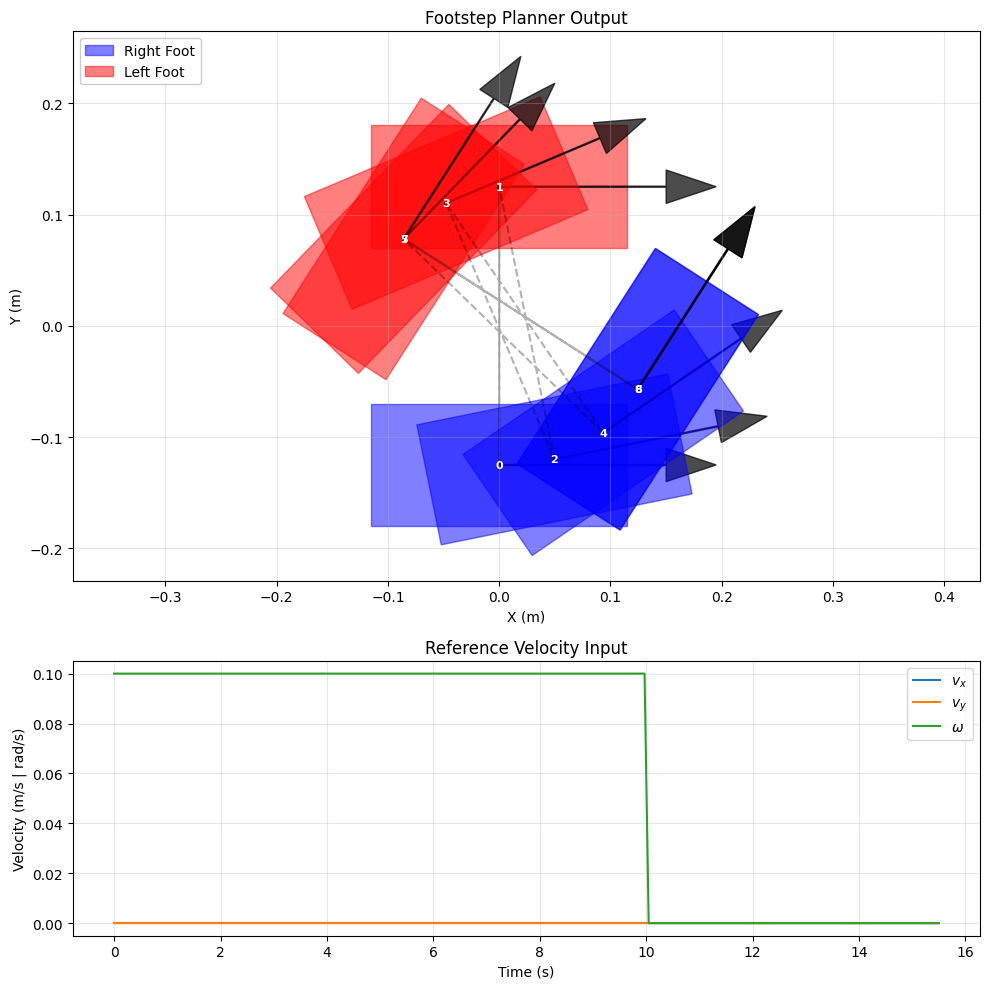

14
Plot saved to: /home/tanawatp/Pictures/Thesis_final/FootstepsPlanned/combined.png


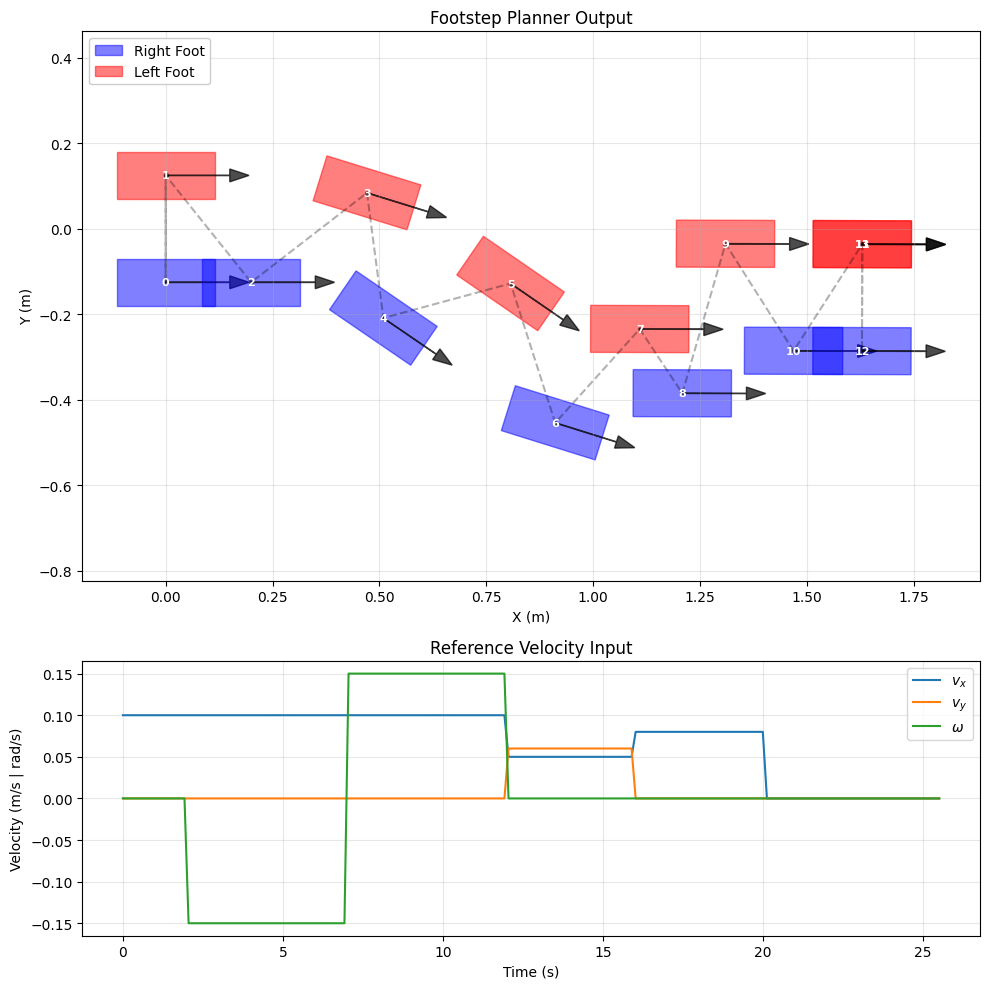

9
Plot saved to: /home/tanawatp/Pictures/Thesis_final/FootstepsPlanned/forward_backward.png


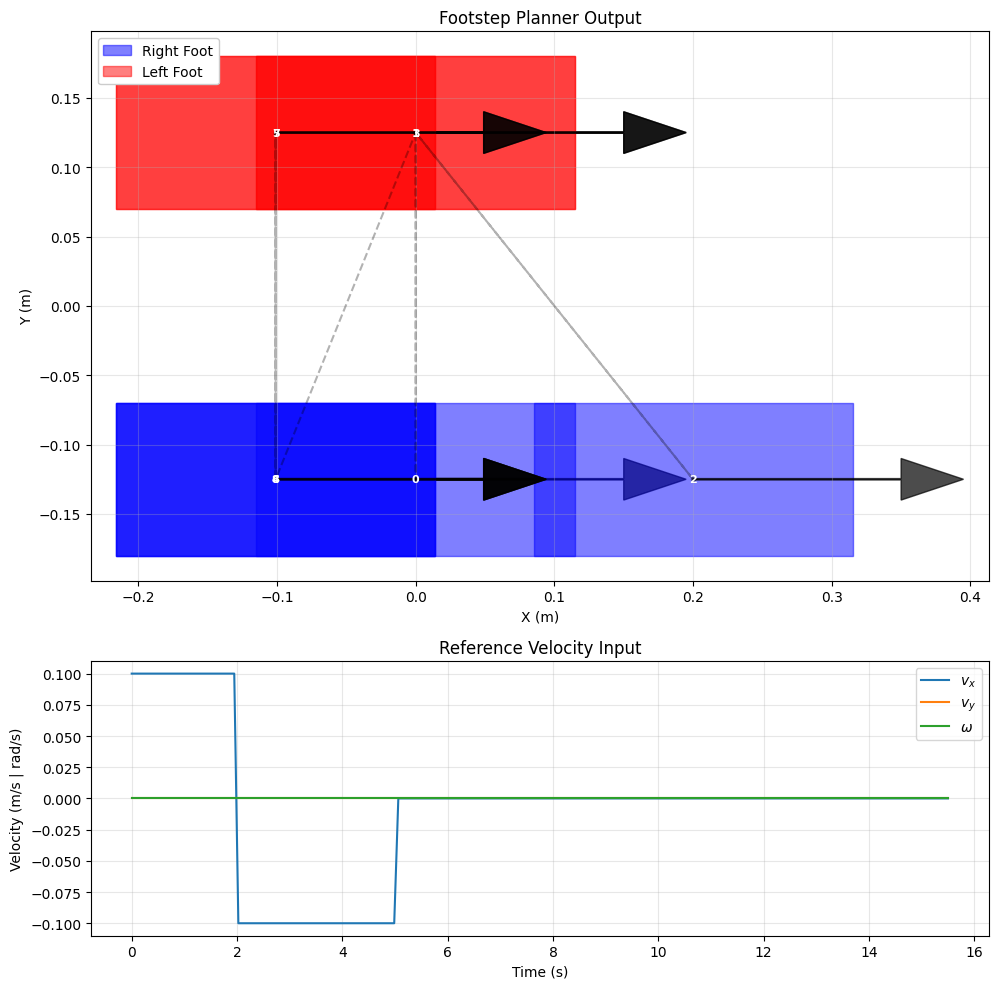

In [3]:
planner = FootstepsPlanner(params=params)

profiles = ["straight", "diagonal", "circular", "rotational", "combined","forward_backward"]
initial_pose = [0.0, 0.125, 0.0]
for profile in profiles:
    VRefCommand=GetVelocityProfile(profile)
    # Generate Plan
    if profile == "combined":
        plan = planner.PlanFootsteps(initial_pose, VRefCommand, 25.0, 'lfoot')
    else:
        plan = planner.PlanFootsteps(initial_pose, VRefCommand, 15.0, 'lfoot')
    print(len(plan))
    # Visualize
    planner.PlotFootsteps(plan, initial_pose,VRefCommand,save_path=f"/home/tanawatp/Pictures/Thesis_final/FootstepsPlanned/{profile}.png")


In [4]:
plan

[{'index': 0,
  'pos': array([ 0.   , -0.125,  0.   ]),
  'ang': array([0., 0., 0.]),
  'ss_duration': 0,
  'ds_duration': 200,
  'foot_id': 'rfoot'},
 {'index': 1,
  'pos': array([0.   , 0.125, 0.   ]),
  'ang': array([0., 0., 0.]),
  'ss_duration': 70,
  'ds_duration': 30,
  'foot_id': 'lfoot'},
 {'index': 2,
  'pos': array([ 0.2  , -0.125,  0.   ]),
  'ang': array([0.00000000e+00, 0.00000000e+00, 2.84527562e-24]),
  'ss_duration': 70,
  'ds_duration': 30,
  'foot_id': 'rfoot'},
 {'index': 3,
  'pos': array([-2.87204532e-15,  1.25000000e-01,  0.00000000e+00]),
  'ang': array([0.00000000e+00, 0.00000000e+00, 1.39955342e-24]),
  'ss_duration': 70,
  'ds_duration': 30,
  'foot_id': 'lfoot'},
 {'index': 4,
  'pos': array([-0.101, -0.125,  0.   ]),
  'ang': array([0.00000000e+00, 0.00000000e+00, 3.44787179e-24]),
  'ss_duration': 70,
  'ds_duration': 30,
  'foot_id': 'rfoot'},
 {'index': 5,
  'pos': array([-0.101,  0.125,  0.   ]),
  'ang': array([0.00000000e+00, 0.00000000e+00, 5.0410082

In [5]:
planner.plan

[{'index': 0,
  'pos': array([ 0.   , -0.125,  0.   ]),
  'ang': array([0., 0., 0.]),
  'ss_duration': 0,
  'ds_duration': 200,
  'foot_id': 'rfoot'},
 {'index': 1,
  'pos': array([0.   , 0.125, 0.   ]),
  'ang': array([0., 0., 0.]),
  'ss_duration': 70,
  'ds_duration': 30,
  'foot_id': 'lfoot'},
 {'index': 2,
  'pos': array([ 0.2  , -0.125,  0.   ]),
  'ang': array([0.00000000e+00, 0.00000000e+00, 2.84527562e-24]),
  'ss_duration': 70,
  'ds_duration': 30,
  'foot_id': 'rfoot'},
 {'index': 3,
  'pos': array([-2.87204532e-15,  1.25000000e-01,  0.00000000e+00]),
  'ang': array([0.00000000e+00, 0.00000000e+00, 1.39955342e-24]),
  'ss_duration': 70,
  'ds_duration': 30,
  'foot_id': 'lfoot'},
 {'index': 4,
  'pos': array([-0.101, -0.125,  0.   ]),
  'ang': array([0.00000000e+00, 0.00000000e+00, 3.44787179e-24]),
  'ss_duration': 70,
  'ds_duration': 30,
  'foot_id': 'rfoot'},
 {'index': 5,
  'pos': array([-0.101,  0.125,  0.   ]),
  'ang': array([0.00000000e+00, 0.00000000e+00, 5.0410082

In [6]:
footstep_planner.plan

NameError: name 'footstep_planner' is not defined

In [ ]:
planner.candidate_footteps.X

AttributeError: 'mFootstepPlanner' object has no attribute 'candidate_footteps'

In [ ]:
planner.candidate_footteps.Y

array([ 0.125, -0.125,  0.125, -0.125])

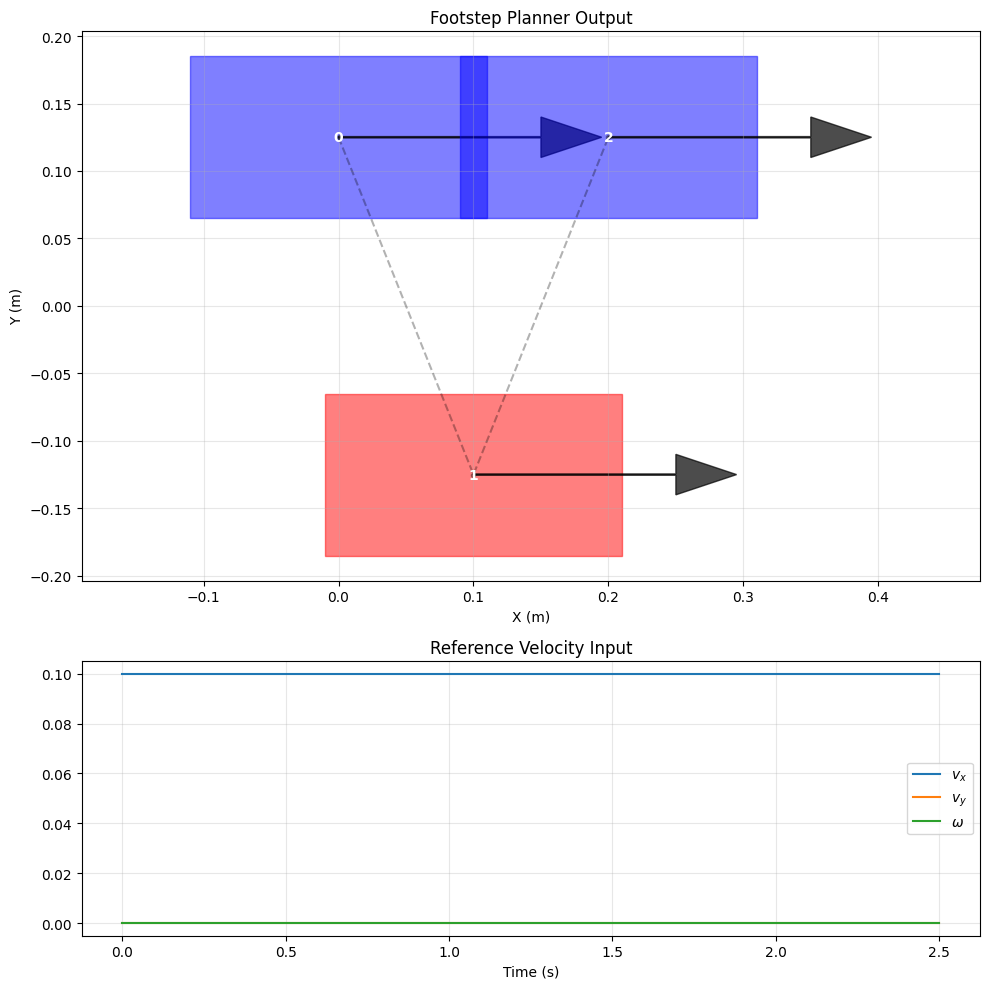

Plotting footsteps at time 1.00 s with idx_offset 0


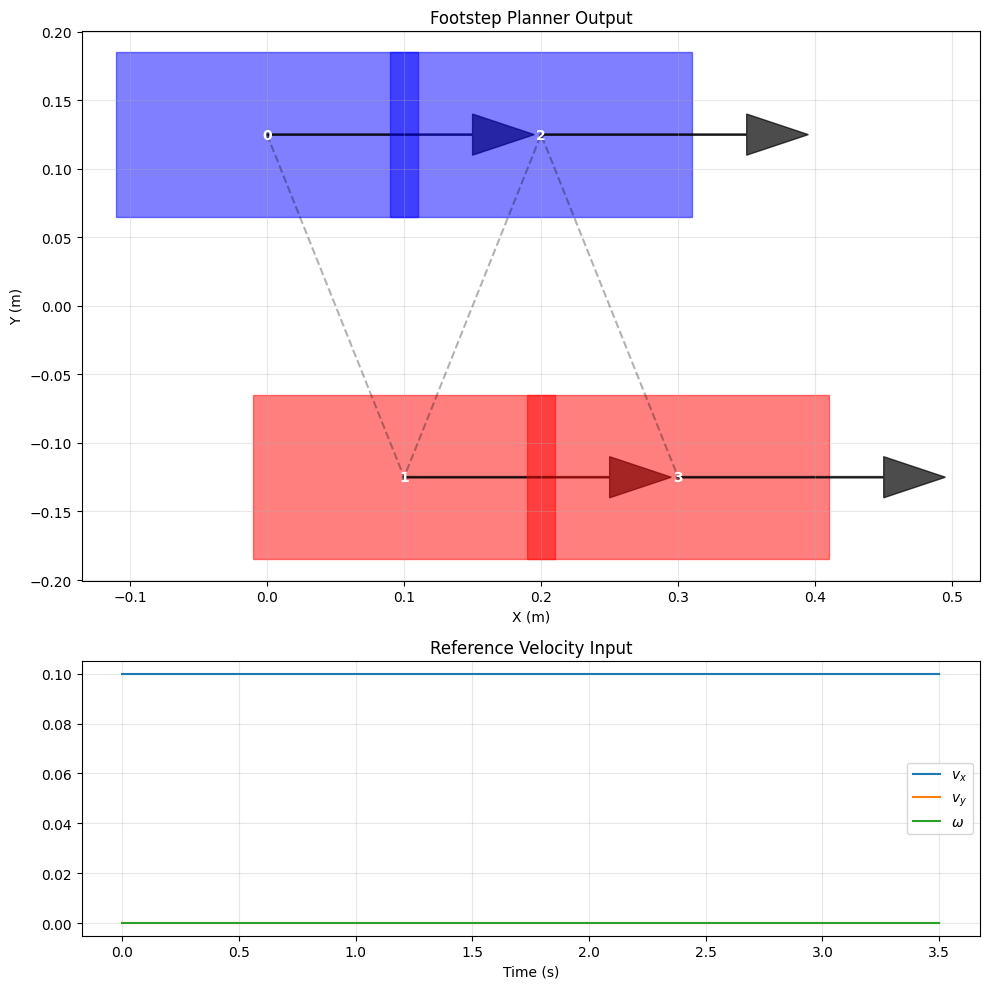

Plotting footsteps at time 2.02 s with idx_offset 1


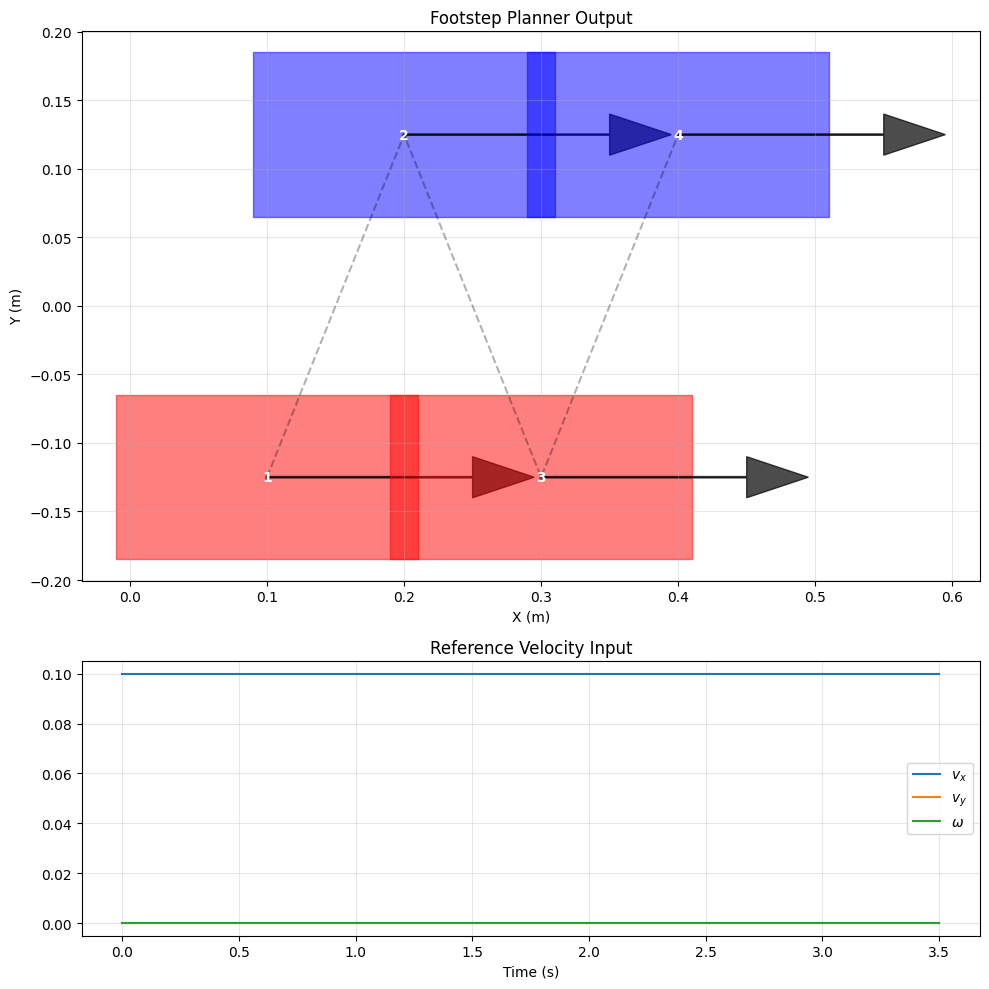

Plotting footsteps at time 3.04 s with idx_offset 2


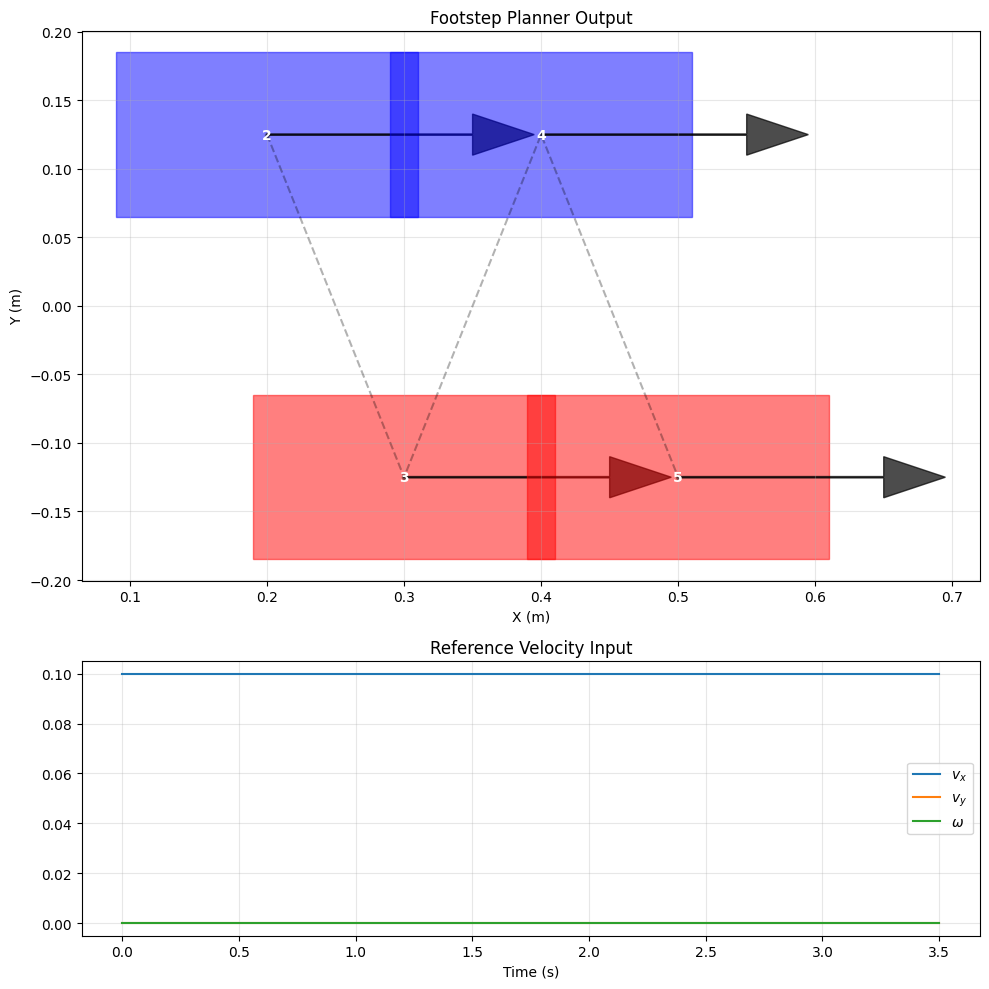

In [ ]:
sim_time = 4.0
dt = 0.02
t_k = 0.0
t_s = 1.0 # Time for each footstep plan
t_relative = 0.0
Tp = 2.0
idx_offset = 0
prev_foot_plan = None
initial_pose = [0.0, 0.125, 0.0]
side = 'left'
phase = [] # 0 for single stance, 1 for double stance
timestamp = []
ds_ratio = 0.2
planner = FootstepPlanner()

# Reference Velocity Function
def VRefCommand(t):
    return [0.1, 0.0, 0.0]
    # if t < 2.0:
    #     return [0.1, 0.1, 0.0]
    # elif t < 5.0:
    #     return [0.1, 0.0, 0.0] 
    # else:
    #     return [0.01, 0.0, 0.0]
foot_planned = planner.PlanFootsteps(initial_pose, VRefCommand, Tp+t_relative, side)
planner.PlotFootsteps(foot_planned, initial_pose, VRefCommand, idx_offset)        
while t_k < sim_time:
    # print(f"Time: {t_k:.2f} s")
    timestamp.append(t_k)
    foot_planned = planner.PlanFootsteps(initial_pose, VRefCommand, Tp+t_relative, side)
    if t_relative < t_s * ds_ratio:
        phase.append(1) # Single Stance
    else:
        phase.append(0) # Double Stance
    if t_relative < 1.0*t_s:
        t_relative += dt
    else:
        print(f"Plotting footsteps at time {t_k:.2f} s with idx_offset {idx_offset}")
        planner.PlotFootsteps(foot_planned, initial_pose, VRefCommand, idx_offset)
        idx_offset += 1
        t_relative = 0.0
        prev_foot_plan = foot_planned
        initial_pose = [prev_foot_plan[0]['x'], prev_foot_plan[0]['y'], prev_foot_plan[0]['theta']] 
        side = prev_foot_plan[0]['side']
        
    t_k += dt

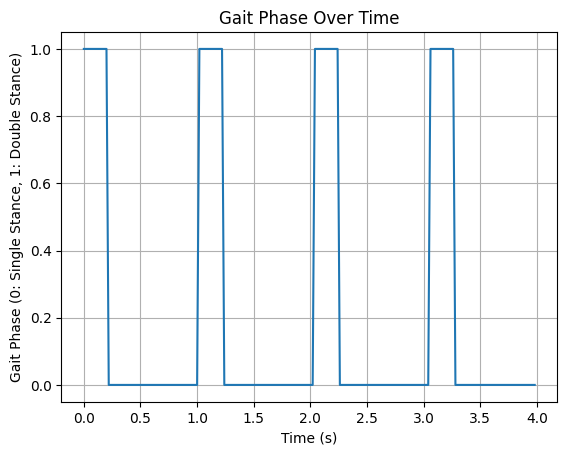

In [ ]:
plt.plot(timestamp, phase)
plt.xlabel('Time (s)')
plt.ylabel('Gait Phase (0: Single Stance, 1: Double Stance)')
plt.title('Gait Phase Over Time')
plt.grid()
plt.show()

Footsteps planning time: 0.0018498897552490234
3


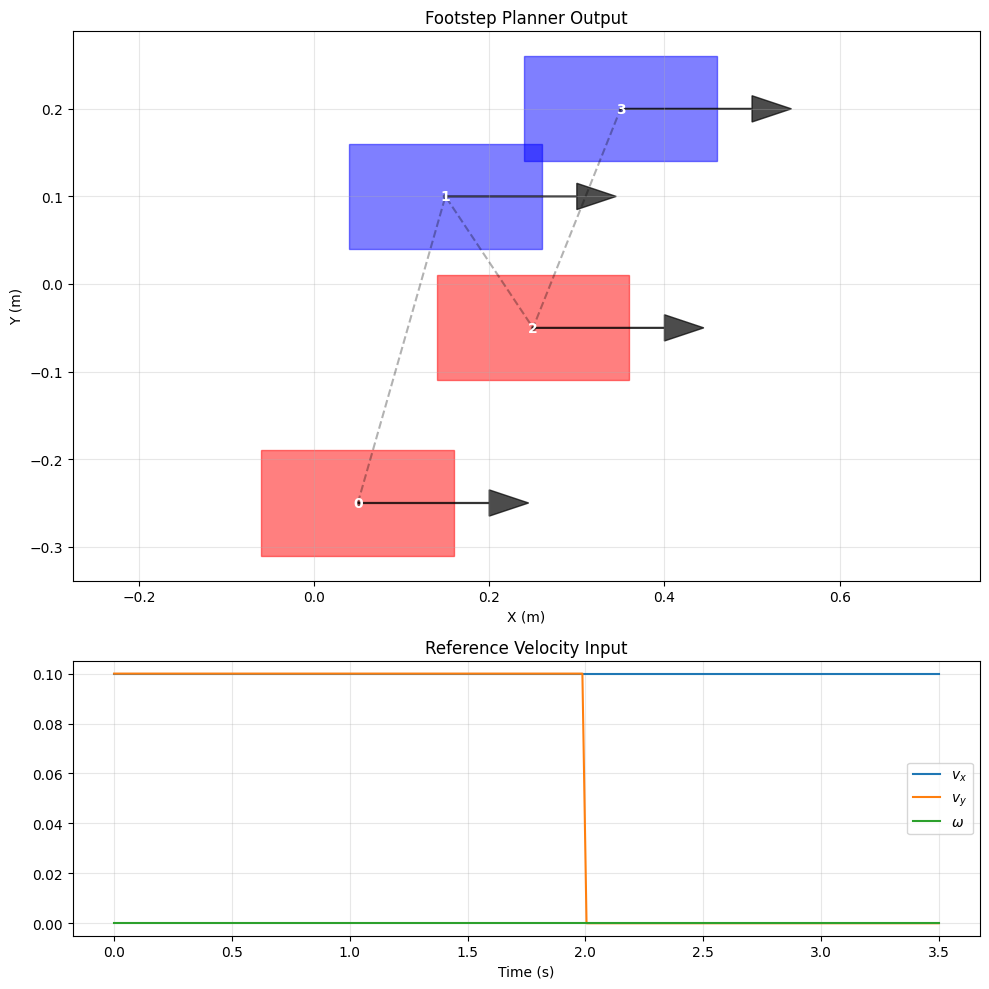

In [ ]:
planner = FootstepPlanner()

# Reference Velocity Function
def VRefCommand(t):
    if t < 2.0:
        return [0.1, 0.1, 0.0]
    elif t < 5.0:
        return [0.1, 0.0, 0.0] 
    else:
        return [0.01, 0.0, 0.0]
        
initial_pose = [0.05, -0.25, 0.0]

# Generate Plan
footsteps_planner_start = time.time()
plan = planner.PlanFootsteps(initial_pose, VRefCommand, 3.0, 'right')
footsteps_planner_end = time.time()
print("Footsteps planning time:", footsteps_planner_end - footsteps_planner_start)
print(len(plan))
# Visualize
planner.PlotFootsteps(plan, initial_pose, VRefCommand)

Footsteps planning time: 0.0015158653259277344
2


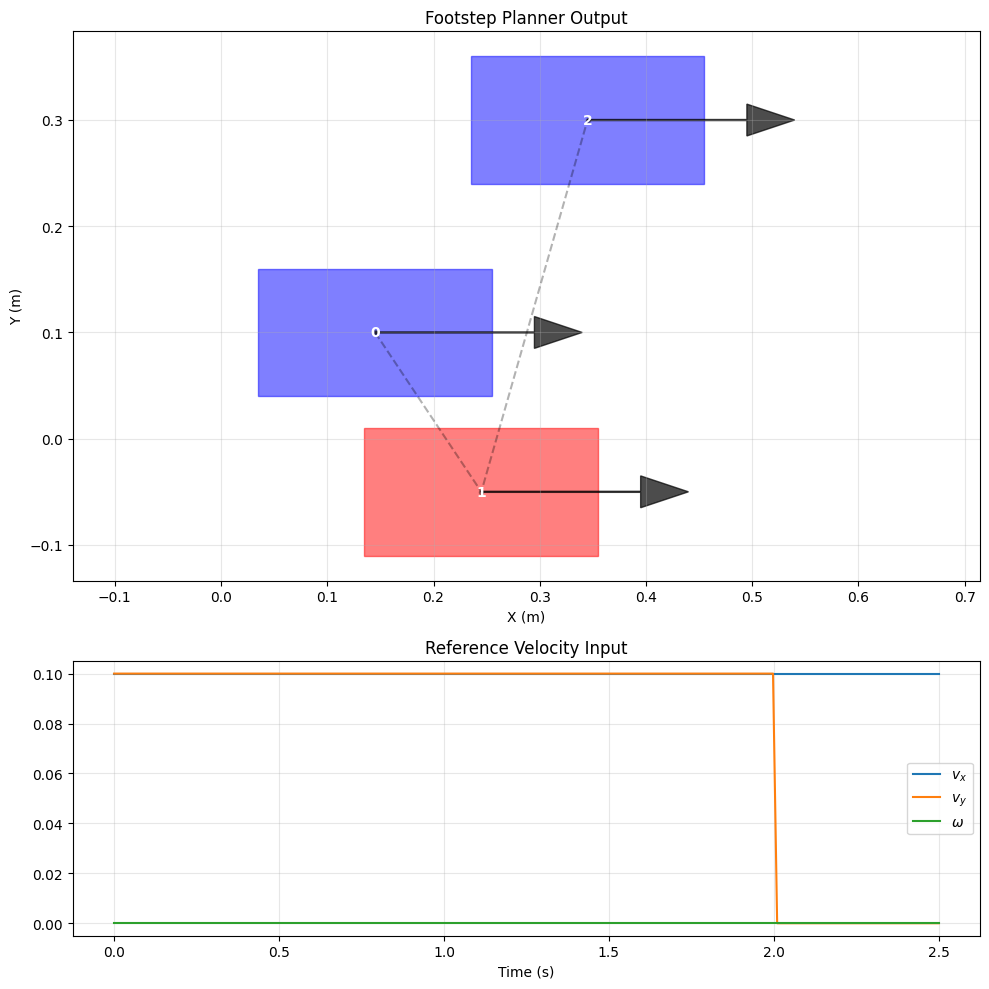

In [ ]:
initial_pose = [0.145, 0.1, 0.0]

# Generate Plan
footsteps_planner_start = time.time()
plan = planner.PlanFootsteps(initial_pose, VRefCommand, 2.0, 'left')
footsteps_planner_end = time.time()
print("Footsteps planning time:", footsteps_planner_end - footsteps_planner_start)
print(len(plan))
# Visualize
planner.PlotFootsteps(plan, initial_pose, VRefCommand)

In [ ]:
plan

[{'index': 1,
  't_start': 0.0,
  't_end': 1.0,
  'x': np.float64(0.2449999998233232),
  'y': np.float64(-0.0500203557321417),
  'theta': np.float64(5.4422578411663174e-24),
  'side': 'right'},
 {'index': 2,
  't_start': 1.0,
  't_end': 2.0,
  'x': np.float64(0.3449999995781203),
  'y': np.float64(0.299959667063596),
  'theta': np.float64(1.2137436936671042e-23),
  'side': 'left'}]

Planning footsteps...
Running IS-MPC Simulation...
IS-MPC Infeasible at t=0.00
IS-MPC Infeasible at t=0.10
IS-MPC Infeasible at t=0.20
IS-MPC Infeasible at t=0.30
IS-MPC Infeasible at t=0.40
IS-MPC Infeasible at t=0.60
IS-MPC Infeasible at t=0.70
IS-MPC Infeasible at t=0.80
IS-MPC Infeasible at t=0.90
IS-MPC Infeasible at t=1.00
IS-MPC Infeasible at t=1.10
IS-MPC Infeasible at t=1.20
IS-MPC Infeasible at t=1.30
IS-MPC Infeasible at t=1.40
IS-MPC Infeasible at t=1.50
IS-MPC Infeasible at t=1.60
IS-MPC Infeasible at t=1.70
IS-MPC Infeasible at t=1.80
IS-MPC Infeasible at t=1.90
IS-MPC Infeasible at t=2.00
IS-MPC Infeasible at t=2.10
IS-MPC Infeasible at t=2.20
IS-MPC Infeasible at t=2.30
IS-MPC Infeasible at t=2.40
IS-MPC Infeasible at t=2.50
IS-MPC Infeasible at t=2.60
IS-MPC Infeasible at t=2.70
IS-MPC Infeasible at t=2.80
IS-MPC Infeasible at t=2.90
IS-MPC Infeasible at t=3.00
IS-MPC Infeasible at t=3.10
IS-MPC Infeasible at t=3.20
IS-MPC Infeasible at t=3.30
IS-MPC Infeasible at t=3.

/tmp/ipykernel_23093/794537817.py:118: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


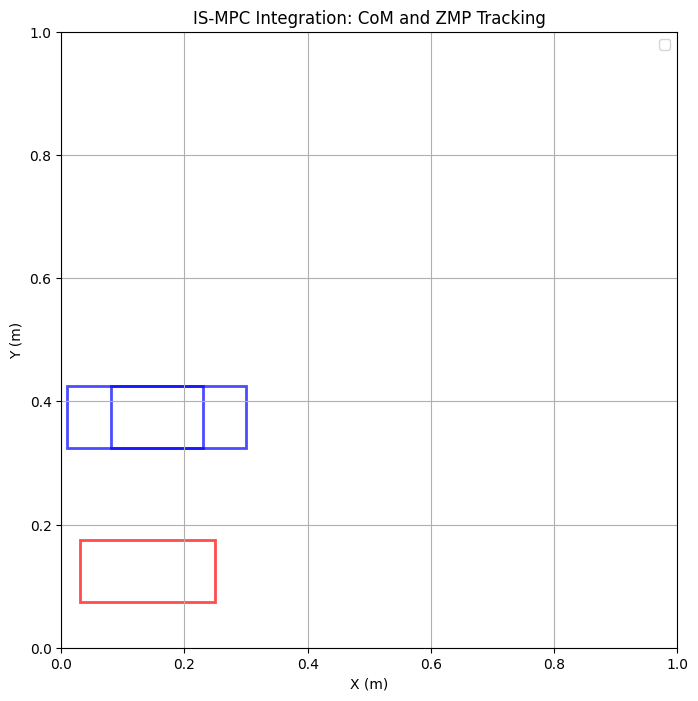

In [ ]:
def RunSimulation():
    # 1. Initialize Planner
    planner = FootstepPlanner()
    
    # Define Reference Velocity (Walk forward then turn)
    def VRefCommand(t):
        if t < 2.0:
            return [0.02, 0.0, 0.0]
        elif t < 5.0:
            return [0.05, 0.0, 0.0] 
        else:
            return [0.01, 0.0, 0.0]
            
    # Plan Footsteps
    init_pose = [0.1, 0.125, 0.0]
    horizon = 3.0
    print("Planning footsteps...")
    footsteps = planner.PlanFootsteps(init_pose, VRefCommand, horizon, 'right')
    
    # 2. Initialize IS-MPC
    mpc = ISMPC()
    
    # Simulation Parameters
    sim_duration = 10.0
    dt_sim = 0.01  # Finer integration than MPC
    t = 0.0
    
    # Initial State [c, c_dot, z]
    # Start CoM above ZMP (static equilibrium)
    x_state = np.array([init_pose[0], 0.0, init_pose[0]]) 
    y_state = np.array([init_pose[1], 0.0, init_pose[1]])
    
    # Storage
    history = {
        't': [], 
        'com_x': [], 'com_y': [],
        'zmp_x': [], 'zmp_y': [],
        'ref_zmp_x': [], 'ref_zmp_y': []
    }
    
    # 3. Control Loop
    print("Running IS-MPC Simulation...")
    mpc_counter = 0
    u_x, u_y = 0.0, 0.0 # Current ZMP velocity input
    
    while t < sim_duration:
        # A. MPC Update (Run at MPC frequency, e.g., 10Hz or defined delta)
        # Here we check if t triggers a new MPC step
        if mpc_counter % int(mpc.delta / dt_sim) == 0:
            u_x, u_y = mpc.Solve(x_state, y_state, t, footsteps)
            
        # B. Dynamics Integration (LIP Model)
        # x_dot = A*x + B*u (Continuous)
        # We use simple Euler for simulation or the exact discretization
        # c_ddot = omega^2 * (c - z)
        # z_dot = u
        
        # X-Axis
        c_x, c_dot_x, z_x = x_state
        c_ddot_x = (mpc.omega**2) * (c_x - z_x)
        
        x_state[0] += c_dot_x * dt_sim
        x_state[1] += c_ddot_x * dt_sim
        x_state[2] += u_x * dt_sim
        
        # Y-Axis
        c_y, c_dot_y, z_y = y_state
        c_ddot_y = (mpc.omega**2) * (c_y - z_y)
        
        y_state[0] += c_dot_y * dt_sim
        y_state[1] += c_ddot_y * dt_sim
        y_state[2] += u_y * dt_sim
        
        # Store Data
        history['t'].append(t)
        history['com_x'].append(x_state[0])
        history['com_y'].append(y_state[0])
        history['zmp_x'].append(x_state[2])
        history['zmp_y'].append(y_state[2])
        
        # Get Ref for plotting
        rx, ry, _, _ = mpc.GetSupportPolygon(t, footsteps)
        history['ref_zmp_x'].append(rx)
        history['ref_zmp_y'].append(ry)
        
        t += dt_sim
        mpc_counter += 1
        
    return history, footsteps

# 4. Visualization
def PlotResults(history, footsteps):
    fig, ax = plt.subplots(figsize=(10, 8))
    
    # Plot Footsteps
    for s in footsteps:
        from matplotlib.patches import Rectangle
        import matplotlib.transforms as transforms
        
        width, height = 0.22, 0.1
        color = 'blue' if s['side'] == 'left' else 'red'
        rect = Rectangle((-width/2, -height/2), width, height, 
                         facecolor='none', edgecolor=color, lw=2, alpha=0.7)
        t = transforms.Affine2D().rotate(s['theta']).translate(s['x'], s['y']) + ax.transData
        rect.set_transform(t)
        ax.add_patch(rect)
        
    # Plot CoM
    # ax.plot(history['com_x'], history['com_y'], 'k-', linewidth=2, label='CoM Trajectory')
    
    # Plot ZMP
    # ax.plot(history['zmp_x'], history['zmp_y'], 'g--', linewidth=1.5, label='ZMP Trajectory')
    
    ax.set_aspect('equal')
    ax.set_xlabel('X (m)')
    ax.set_ylabel('Y (m)')
    ax.set_title('IS-MPC Integration: CoM and ZMP Tracking')
    ax.legend()
    ax.grid(True)
    plt.show()

hist, steps = RunSimulation()
PlotResults(hist, steps)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
# from UtilsFunction.IntrinsicallyStableMPC.temp1 import *  # moved to legacy/ (not importable from volta)
# --- Simulation Parameters ---
dt = 0.01          # Control period (s)
sim_time = 5.0     # Total simulation duration (s)
h_c = 0.8          # CoM height (m)
horizon = 80       # MPC horizon steps (0.8s)
foot_width = 0.1   # Support polygon width (m)
foot_length = 0.2  # Support polygon length (m)

# Instantiate the controller (Assuming the class from previous report is available)
# dims = (foot_length, foot_width)
controller = ISMPC(com_height=h_c, horizon_steps=horizon, dt=dt, foot_dims=(0.2, 0.1))

# Define a simple footstep plan: (x, y, theta, start_time)
# Alternating feet: Right (y=-0.1), Left (y=0.1)
planner = FootstepPlanner()

# Define Reference Velocity (Walk forward then turn)
def VRefCommand(t):
    if t < 2.0:
        return [0.02, 0.0, 0.0]
    elif t < 5.0:
        return [0.05, 0.0, 0.0] 
    else:
        return [0.01, 0.0, 0.0]
        
# Plan Footsteps
init_pose = [0.1, 0.125, 0.0]
horizon = 3.0
print("Planning footsteps...")
footstep_plan = planner.PlanFootsteps(init_pose, VRefCommand, horizon, 'right')

# --- State Initialization ---
# State: [cx, dcx, zx, cy, dcy, zy]
state = np.array([0.0, 0.0, 0.0, -0.1, 0.0, -0.1])
history = []

# --- Simulation Loop ---
for t in np.arange(0, sim_time, dt):
    # 1. Solve IS-MPC
    # Returns optimal ZMP velocities for the current horizon
    u_x_opt, u_y_opt = controller.solve(state, footstep_plan, tail_type="anticipative")
    
    # 2. Extract first control input
    ux = u_x_opt
    uy = u_y_opt
    
    # 3. Save history for plotting
    history.append(np.concatenate(([t], state)))
    
    # 4. Update State (LIP Dynamics Integration)
    # Using the discrete-time transition matrices A_d, B_d
    state_x = controller.A_d @ state[0:3] + controller.B_d.flatten() * ux
    state_y = controller.A_d @ state[3:6] + controller.B_d.flatten() * uy
    state = np.concatenate((state_x, state_y))

history = np.array(history)

Planning footsteps...


ValueError: operands could not be broadcast together with shapes (3,) (80,) 

In [ ]:
def plot_results(history, plan):
    t = history[:, 0]
    cx, dcx, zx = history[:, 1], history[:, 2], history[:, 3]
    cy, dcy, zy = history[:, 4], history[:, 5], history[:, 6]
    
    # Calculate DCM (Divergent Component of Motion) for stability check
    eta = np.sqrt(9.81 / h_c)
    dcm_x = cx + dcx / eta
    dcm_y = cy + dcy / eta

    plt.figure(figsize=(12, 8))

    # --- Plot 1: XY Plane Ground Track ---
    plt.subplot(2, 1, 1)
    plt.plot(cx, cy, 'b-', label='CoM Path')
    plt.plot(zx, zy, 'r--', label='ZMP Path')
    plt.plot(dcm_x, dcm_y, 'g:', label='DCM (Capture Point)')
    
    # Plot Footsteps
    for fs in plan:
        rect = plt.Rectangle((fs - 0.1, fs[1] - 0.05), 0.2, 0.1, 
                             fill=False, color='black', alpha=0.5)
        plt.gca().add_patch(rect)
    
    plt.title("Humanoid Ground Track (XY Plane)")
    plt.xlabel("X [m]")
    plt.ylabel("Y [m]")
    plt.legend()
    plt.axis('equal')
    plt.grid(True)

    # --- Plot 2: Sagittal (X) Time Series ---
    plt.subplot(2, 1, 2)
    plt.plot(t, cx, label='CoM X')
    plt.plot(t, zx, label='ZMP X')
    plt.plot(t, dcm_x, label='DCM X', alpha=0.6)
    plt.title("Sagittal Dynamics vs Time")
    plt.xlabel("Time [s]")
    plt.ylabel("Position [m]")
    plt.legend()
    plt.grid(True)

    plt.tight_layout()
    plt.show()

plot_results(history, footstep_plan)